In [35]:
# import libraries
import pandas as pd
import random as rnd
import numpy as np
import matplotlib.pyplot as plt
# import squarify
from matplotlib.ticker import FuncFormatter
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors
import seaborn as sns

from datetime import datetime, timedelta
import logging
import os

%matplotlib inline

# setting up pseudo-random numbers for python standard and numpy random module.
rnd.seed(1234) 
rng = np.random.default_rng(seed=1234)

pd.set_option('display.max_columns',None) # setting up the dataframe display columns
pd.set_option('display.max_colwidth', 100) # setting up column width 100

### Loading dataset

In [36]:
file_ndcp = "nationaldatabaseofchildcareprices.xlsx"

# Catch any exception reading file
try: 
    df_ndcp = pd.read_excel(f'{file_dir}/{file_ndcp}', sheet_name = "nationaldatabaseofchildcare" ) 
except FileNotFoundError: # if file is not not found. 
    logging.error(f"Error: The file '{file_ndcp}' was not found.")

In [37]:
df_ndcp.head()

,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,MUNR_20to64,FLFPR_20to64,FLFPR_20to64_Under6,FLFPR_20to64_6to17,FLFPR_20to64_Under6_6to17,MLFPR_20to64,PR_F,PR_P,MHI,ME,FME,MME,MHI_2018,ME_2018,FME_2018,MME_2018,TotalPop,OneRace,OneRace_W,OneRace_B,OneRace_I,OneRace_A,OneRace_H,OneRace_Other,TwoRaces,Hispanic,Households,H_Under6_BothWork,H_Under6_FWork,H_Under6_MWork,H_Under6_SingleM,H_6to17_BothWork,H_6to17_Fwork,H_6to17_Mwork,H_6to17_SingleM,EMP_M,MEMP_M,FEMP_M,EMP_Service,MEMP_Service,FEMP_Service,EMP_Sales,MEMP_Sales,FEMP_Sales,EMP_N,MEMP_N,FEMP_N,EMP_P,MEMP_P,FEMP_P,iUNR_16,iFUNR_16,iMUNR_16,iUNR_20to64,iFUNR_20to64,iMUNR_20to64,iFLFPR_20to64,iFLFPR_20to64_Under6,iFLFPR_20to64_6to17,iFLFPR_20to64_Under6_6to17,iMLFPR_20to64,iPR_F,iPR_P,iMHI,iME,iFME,iMME,iMHI_2018,iME_2018,iFME_2018,iMME_2018,iTotalPop,iOneRace,iOneRace_W,iOneRace_B,iOneRace_I,iOneRace_A,iOneRace_H,iOneRace_Other,iTwoRaces,iHispanic,iHouseholds,iH_Under6_BothWork,iH_Under6_FWork,iH_Under6_MWork,iH_Under6_SingleM,iH_6to17_BothWork,iH_6to17_Fwork,iH_6to17_Mwork,iH_6to17_SingleM,iEMP_M,iMEMP_M,iFEMP_M,iEMP_Service,iMEMP_Service,iFEMP_Service,iEMP_Sales,iMEMP_Sales,iFEMP_Sales,iEMP_N,iMEMP_N,iFEMP_N,iEMP_P,iMEMP_P,iFEMP_P,MCBto5,MC6to11,MC12to17,MC18to23,MC24to29,MC30to35,MC36to41,MC42to47,MC48to53,MC54toSA,MCSA,MFCCBto5,MFCC6to11,MFCC12to17,MFCC18to23,MFCC24to29,MFCC30to35,MFCC36to41,MFCC42to47,MFCC48to53,MFCC54toSA,MFCCSA,_75CBto5,_75C6to11,_75C12to17,_75C18to23,_75C24to29,_75C30to35,_75C36to41,_75C42to47,_75C48to53,_75C54toSA,_75CSA,_75FCCBto5,_75FCC6to11,_75FCC12to17,_75FCC18to23,_75FCC24to29,_75FCC30to35,_75FCC36to41,_75FCC42to47,_75FCC48to53,_75FCC54toSA,_75FCCSA,iMCBto5,iMC6to11,iMC12to17,iMC18to23,iMC24to29,iMC30to35,iMC36to41,iMC42to47,iMC48to53,iMC54toSA,iMCSA,iMFCCBto5,iMFCC6to11,iMFCC12to17,iMFCC18to23,iMFCC24to29,iMFCC30to35,iMFCC36to41,iMFCC42to47,iMFCC48to53,iMFCC54toSA,iMFCCSA,i_75CBto5,i_75C6to11,i_75C12to17,i_75C18to23,i_75C24to29,i_75C30to35,i_75C36to41,i_75C42to47,i_75C48to53,i_75C54toSA,i_75CSA,i_75FCCBto5,i_75FCC6to11,i_75FCC12to17,i_75FCC18to23,i_75FCC24to29,i_75FCC30to35,i_75FCC36to41,i_75FCC42to47,i_75FCC48to53,i_75FCC54toSA,i_75FCCSA,MCInfant,MCInfant_flag,MCToddler,MCToddler_flag,MCPreschool,MCPreschool_flag,_75CInfant,_75CInfant_flag,_75CToddler,_75CToddler_flag,_75CPreschool,_75CPreschool_flag,MFCCInfant,MFCCInfant_flag,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
0,Alabama,AL,Autauga County,1001,2008,5.42,4.41,6.32,4.6,3.5,5.6,68.9,66.9,79.59,60.81,84.0,8.5,11.5,50837.0,28444.0,21875.0,36032.0,58462.55,32710.60,25156.25,41436.80,49744,98.1,78.9,17.7,0.4,0.4,0.0,0.7,1.9,1.8,18373,1543,970,22,995.0,4900,1308,114,1966.0,27.40,24.41,30.68,17.06,15.53,18.75,29.11,15.97,43.52,13.21,22.54,2.99,13.22,21.55,4.07,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,104.95,104.95,104.95,104.95,104.95,85.92,85.92,85.92,85.92,85.92,80.92,83.45,83.45,83.45,83.45,83.45,81.40,81.40,81.40,81.40,81.40,81.40,125.8,125.8,125.8,125.8,125.8,103.0,103.0,103.0,103.0,103.0,97.0,97.4,97.4,97.4,97.4,97.4,95.0,95.0,95.0,95.0,95.0,95.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,11.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,104.95,1.0,104.95,3.0,85.92,1.0,125.8,1.0,125.8,3.0,103.0,1.0,83.45,1.0,83.45,3.0,81.40,1.0,97.4,1.0,97.4,3.0,95.0,1.0
1,Alabama,AL,Autauga County,1001,2009,5.93,5.72,6.11,4.8,4.6,5.0,70.8,63.7,78.41,59.91,86.2,7.5,10.3,51463.0,29648.0,22951.0,37492.0,60211.71,34688.16,26852.67,43865.64,49584,98.6,79.1,17.9,0.4,0.6,0.0,0.7,1.4,2.0,18288,1475,964,16,1099.0,5028,1519,92,2305.0,29.54,26.07,33.40,15.81,14.16,17.64,28.75,17.51,41.25,11.89,20.30,2.52,14.02,21.96,5.19,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1

In [38]:
df_ndcp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34567 entries, 0 to 34566
Columns: 227 entries, State_Name to _75FCCPreschool_flag
dtypes: float64(159), int64(65), object(3)
memory usage: 59.9+ MB


It is a big dataset, and has 227 columns and 34567 rows.

### Exploratroy Data Analysis

In [39]:
print("National Database of Childcare Prices dataset:")
print(f'Rows    : {df_ndcp.shape[0]:,}')
print(f'Columns : {df_ndcp.shape[1]}')
print(f'Years   : {df_ndcp["StudyYear"].min()} – {df_ndcp["StudyYear"].max()}')
print(f'States  : {df_ndcp["State_Name"].nunique()}')
print(f'Counties: {df_ndcp["County_Name"].nunique()}')

National Database of Childcare Prices dataset:
Rows    : 34,567
Columns : 227
Years   : 2008 – 2018
States  : 51
Counties: 1879


In [40]:
# Printing first 4 rows of the keys columns
key_cols = ['State_Name','County_Name','StudyYear','MCInfant','MFCCInfant',
            'MHI_2018','FME_2018','FLFPR_20to64_Under6','PR_P']
df_ndcp[key_cols].head(4)

,State_Name,County_Name,StudyYear,MCInfant,MFCCInfant,MHI_2018,FME_2018,FLFPR_20to64_Under6,PR_P
0,Alabama,Autauga County,2008,104.95,83.45,58462.55,25156.25,66.9,11.5
1,Alabama,Autauga County,2009,105.11,87.39,60211.71,26852.67,63.7,10.3
2,Alabama,Autauga County,2010,105.28,91.33,61775.80,27391.08,67.0,10.6
3,Alabama,Autauga County,2011,105.45,95.28,60366.88,26727.68,66.5,10.9


In [41]:
# Keys columns for story and audience
key_cols = [
    'MCInfant', 'MCToddler', 'MCPreschool', 'MCSA',
    'MFCCInfant', 'MFCCToddler', 'MFCCPreschool', 'MFCCSA',
    'MHI_2018', 'FME_2018', 'MME_2018',
    'FLFPR_20to64_Under6', 'FLFPR_20to64_6to17',
    'H_Under6_BothWork', 'H_Under6_SingleM',
    'PR_P', 'PR_F', 'TotalPop'
]

missing = df_ndcp[key_cols].isnull().sum()
missing_pct = (missing / len(df_ndcp) * 100).round(2)

missing_df = pd.DataFrame({'Missing Count': missing,'Missing %': missing_pct}
                         ).sort_values('Missing %', ascending=False)
print(missing_df)


                     Missing Count  Missing %
MFCCInfant                   11184      32.35
MFCCToddler                  11184      32.35
MFCCPreschool                11184      32.35
MFCCSA                       11184      32.35
MCInfant                     10974      31.75
MCPreschool                  10974      31.75
MCSA                         10974      31.75
MCToddler                    10974      31.75
H_Under6_SingleM                 2       0.01
H_Under6_BothWork                0       0.00
PR_F                             0       0.00
PR_P                             0       0.00
FME_2018                         0       0.00
FLFPR_20to64_6to17               0       0.00
FLFPR_20to64_Under6              0       0.00
MME_2018                         0       0.00
MHI_2018                         0       0.00
TotalPop                         0       0.00


Missing values in price columns are expected, not all counties reported data every year.

I am not deleting any NaN values here.

In [42]:
# Descriptive statistics for Childcare Price
print('Childcre Price statistics(weekly $):')
price_cols = ['MCInfant','MCToddler','MCPreschool','MCSA',
              'MFCCInfant','MFCCToddler','MFCCPreschool','MFCCSA']

df_ndcp[price_cols].describe().round(2)

Childcre Price statistics(weekly $):


,MCInfant,MCToddler,MCPreschool,MCSA,MFCCInfant,MFCCToddler,MFCCPreschool,MFCCSA
count,23593.00,23593.00,23593.00,23593.00,23383.00,23383.00,23383.00,23383.00
mean,146.05,130.48,122.23,101.23,113.42,106.76,104.19,92.52
std,53.70,43.78,38.54,34.55,32.82,29.98,28.96,27.67
min,27.73,21.54,21.54,18.98,43.08,43.08,40.03,22.00
25%,108.75,100.00,95.88,78.65,90.00,85.08,84.26,75.00
50%,134.50,120.99,113.99,96.53,106.00,100.25,99.65,88.18
75%,166.33,148.71,139.30,119.38,129.32,124.95,120.20,107.50
max,470.00,419.00,385.00,375.40,430.94,376.32,331.34,308.00


* Infant childcare is the most expensive. Center-based infant care (MCInfant) averages $146/week.

* Center-based care costs more than home-based at every age.

* The median infant center cost is \\$134.50 vs \\$106.00 for home-based (MFCCInfant), a \$28.50/week difference.

In [43]:
df = df_ndcp.copy()

In [44]:
# Annual cost of infant center-based care (weekly × 52)
df['annual_mc_infant'] = df['MCInfant'] * 52

# Cost as % of median household income
df['infant_pct_income'] = (df['annual_mc_infant'] / df_ndcp['MHI_2018'] * 100).round(2)

# Gender pay gap within counties
df['gender_pay_gap'] = ((df['MME_2018'] - df['FME_2018']) / df['MME_2018'] * 100).round(2)

print('Annual Infant Care Cost as % of household income')
print(df['infant_pct_income'].describe().round(2))
print()
print(f"Average: {df['infant_pct_income'].mean():.1f}% of household income")
print(f"Affordable benchmark (HHS definition): 7%")
print(f"Counties where cost > 10% of income: "
      f"{(df['infant_pct_income'] > 10).sum():,} "
      f"({(df['infant_pct_income'] > 10).mean()*100:.1f}% of records)")
print(f"Counties where cost > 20% of income: "
      f"{(df['infant_pct_income'] > 20).sum():,} "
      f"({(df['infant_pct_income'] > 20).mean()*100:.1f}% of records)")

Annual Infant Care Cost as % of household income
count    23593.00
mean        15.18
std          4.32
min          3.27
25%         12.25
50%         14.65
75%         17.32
max         54.30
Name: infant_pct_income, dtype: float64

Average: 15.2% of household income
Affordable benchmark (HHS definition): 7%
Counties where cost > 10% of income: 21,672 (62.7% of records)
Counties where cost > 20% of income: 2,659 (7.7% of records)


In [45]:
BG_CARD  = 'aliceblue'        
BG_FIG   = 'white'           
C_VALUE  = '#0C447C' # 'darkblue'  
C_LABEL  = 'darkslategray'   
C_SUB    = 'dimgray'          
C_BORDER = 'lightsteelblue'

#### P1- Banner Chart

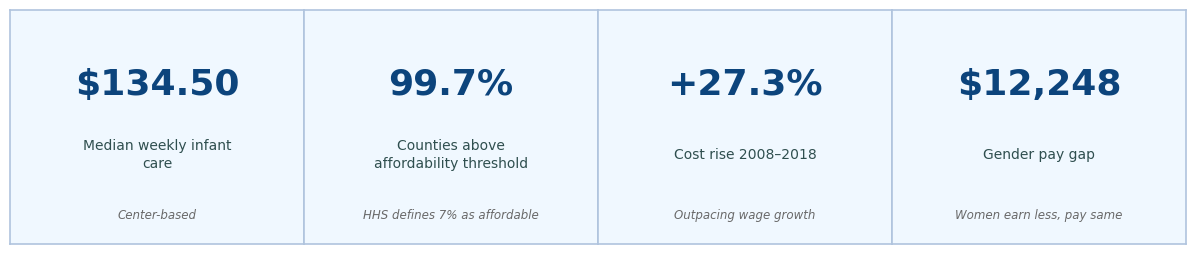

In [46]:
# Median weekly infant center-based care
median_weekly = df['MCInfant'].median()
stat1_value   = f'${median_weekly:,.2f}'
stat1_label   = 'Median weekly infant\ncare'
stat1_sub     = 'Center-based'

# % of counties above HHS 7% affordability threshold
df['annual_mc_infant']  = df['MCInfant'] * 52
df['infant_pct_income'] = (df['annual_mc_infant'] / df['MHI_2018'] * 100)
pct_above_7 = (df['infant_pct_income'].dropna() > 7).mean() * 100
stat2_value  = f'{pct_above_7:.1f}%'
stat2_label  = 'Counties above\naffordability threshold'
stat2_sub    = 'HHS defines 7% as affordable'

# Cost rise 2008 to 2018
cost_2008    = df[df['StudyYear'] == 2008]['MCInfant'].median()
cost_2018    = df[df['StudyYear'] == 2018]['MCInfant'].median()
pct_rise     = ((cost_2018 - cost_2008) / cost_2008) * 100
stat3_value  = f'+{pct_rise:.1f}%'
stat3_label  = f'Cost rise 2008–2018'
stat3_sub    = 'Outpacing wage growth'

# Gender pay gap
median_male   = df['MME_2018'].median()
median_female = df['FME_2018'].median()
pay_gap       = median_male - median_female
stat4_value   = f'${pay_gap:,.0f}'
stat4_label   = 'Gender pay gap'
stat4_sub     = 'Women earn less, pay same'

stats = [
    {'value': stat1_value, 'label': stat1_label, 'sublabel': stat1_sub},
    {'value': stat2_value, 'label': stat2_label, 'sublabel': stat2_sub},
    {'value': stat3_value, 'label': stat3_label, 'sublabel': stat3_sub},
    {'value': stat4_value, 'label': stat4_label, 'sublabel': stat4_sub},
]

fig, axes = plt.subplots(1, 4, figsize=(12, 2.6))
fig.patch.set_facecolor(BG_FIG)
plt.subplots_adjust(wspace=0, left=0.01, right=0.99, top=0.95, bottom=0.05)

for ax, stat in zip(axes, stats):
    ax.set_facecolor(BG_CARD)
    for spine in ax.spines.values():
        spine.set_edgecolor(C_BORDER)
        spine.set_linewidth(1.2)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(0.5, 0.68, stat['value'],
            transform=ax.transAxes, ha='center', va='center',
            fontsize=26, fontweight='bold', color=C_VALUE)
    ax.text(0.5, 0.38, stat['label'],
            transform=ax.transAxes, ha='center', va='center',fontsize=10, 
            color=C_LABEL, linespacing=1.4)
    ax.text(0.5, 0.12, stat['sublabel'],transform=ax.transAxes, 
            ha='center', va='center',fontsize=8.5, fontstyle='italic', 
            color=C_SUB, linespacing=1.3)
plt.show()

HHS = U.S. Department of Health and Human Services

https://www.childcareaware.org/our-issues/public-policy/child-care-access-and-affordability/

The median weekly cost of infant center-based care is $134.50. 

- Childcare prices rose 27.3% nationally between 2008 and 2018.
- A woman earns $12,248 less per year than a man, but she pays the same childcare 
costs.
- 99.7% of U.S. counties had childcare costs above the federal affordability threshold.

In [47]:
# Color palette 
SBLUE  = 'steelblue'
CBLUE  = 'cornflowerblue'
TOMATO = 'tomato'
SALMON = 'salmon'
TEAL   = 'teal'
ORANGE = '#E07B39'
AMBER  = 'darkgoldenrod'
BLACK  = 'black'
DARK   = 'dimgray'
GRAY   = 'gray'
LIGHT  = 'lightgray'

# Banner card colors 
BG_CARD  = 'aliceblue'
C_VALUE  = '#0C447C'
C_LABEL  = 'darkslategray'
C_SUB    = 'dimgray'
C_BORDER = 'lightsteelblue'

SOURCE = 'Source: U.S. Department of Labor, Women\'s Bureau — National Database of Childcare Prices (2008–2018)'

In [48]:
# Build on df and add any missing derived columns
df['annual_mc_infant']   = df['MCInfant']  * 52
df['annual_mfcc_infant'] = df['MFCCInfant'] * 52
df['infant_pct_income']  = (df['annual_mc_infant'] / df['MHI_2018'] * 100).round(2)
df['gender_pay_gap']     = (df['MME_2018'] - df['FME_2018'])

print(f'Rows    : {len(df):,}')
print(f'Years   : {df.StudyYear.min()} – {df.StudyYear.max()}')
print(f'States  : {df.State_Name.nunique()}')

Rows    : 34,567
Years   : 2008 – 2018
States  : 51


In [49]:
def style_ax(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color(LIGHT)
    ax.spines['bottom'].set_color(LIGHT)
    ax.tick_params(colors=DARK, labelsize=9)
    ax.grid(False)

#### P2- Line Chart

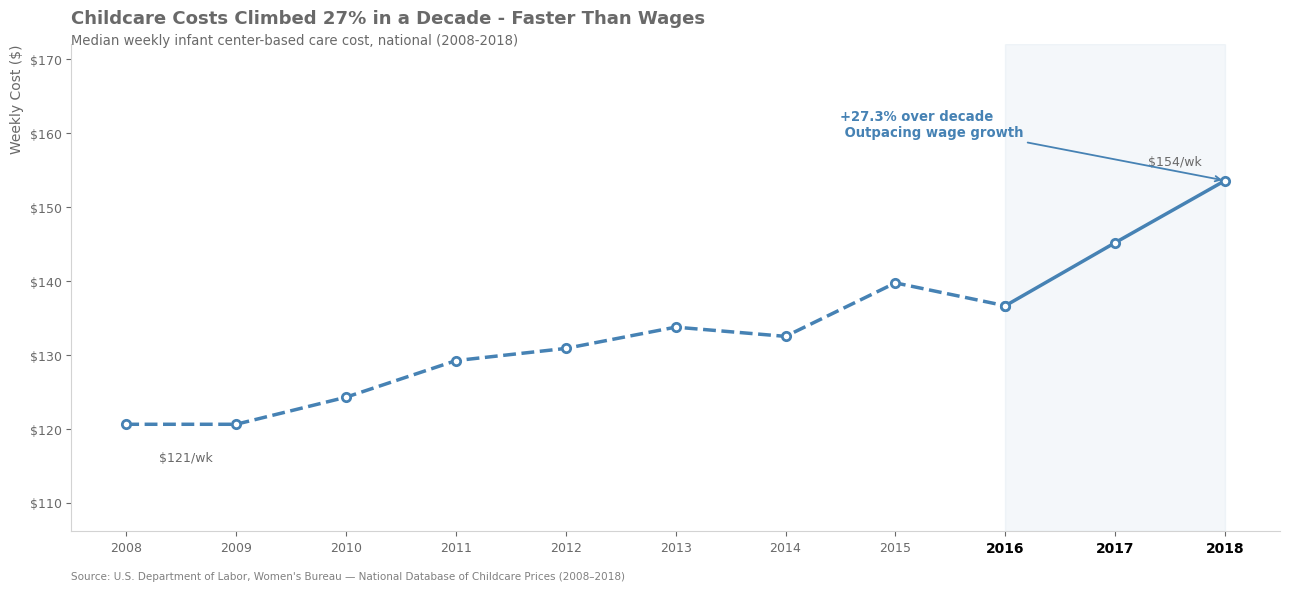

In [50]:
yearly = (df.groupby('StudyYear')['MCInfant']
            .median()
            .reset_index()
            .rename(columns={'MCInfant': 'median_cost'}))
 
pct_rise = ((yearly.iloc[-1]['median_cost'] - yearly.iloc[0]['median_cost'])
            / yearly.iloc[0]['median_cost'] * 100)
 
# Masks 2015 is shared connection point between dashed and solid
mask_pre  = yearly['StudyYear'] <= 2016
mask_last = yearly['StudyYear'] >= 2016
 
# Chart
fig, ax = plt.subplots(figsize=(13, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
style_ax(ax)
 
# Shade 2015-2018
ax.axvspan(2016, 2018, alpha=0.06, color=SBLUE, zorder=0)
 
# Dashed line 2008-2015
ax.plot(yearly[mask_pre]['StudyYear'], yearly[mask_pre]['median_cost'],
        color=SBLUE, linewidth=2.5, linestyle='--',
        marker='o', markersize=6,
        markerfacecolor='white', markeredgecolor=SBLUE, markeredgewidth=2)
 
# Solid line 2015-2018
ax.plot(yearly[mask_last]['StudyYear'], yearly[mask_last]['median_cost'],
        color=SBLUE, linewidth=2.5, linestyle='-',
        marker='o', markersize=6,
        markerfacecolor='white', markeredgecolor=SBLUE, markeredgewidth=2)
 
# Annotate first and last
ax.annotate(f"${yearly.iloc[0]['median_cost']:.0f}/wk",
            xy=(yearly.iloc[0]['StudyYear'], yearly.iloc[0]['median_cost']),
            xytext=(2008.3, yearly.iloc[0]['median_cost'] - 5),
            fontsize=9, color=DARK)
ax.annotate(f"${yearly.iloc[-1]['median_cost']:.0f}/wk",
            xy=(yearly.iloc[-1]['StudyYear'], yearly.iloc[-1]['median_cost']),
            xytext=(2017.3, yearly.iloc[-1]['median_cost'] + 2),
            fontsize=9, color=DARK)
 
# Key callout
peak_yr  = yearly.loc[yearly['median_cost'].idxmax(), 'StudyYear']
peak_val = yearly['median_cost'].max()
ax.annotate(f'+{pct_rise:.1f}% over decade\n Outpacing wage growth',
            xy=(peak_yr, peak_val),
            xytext=(2014.5, peak_val + 6 ),
            fontsize=9.5, color=SBLUE, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=SBLUE, lw=1.3))
 
# Titles
ax.set_title('Childcare Costs Climbed 27% in a Decade - Faster Than Wages',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=15)
ax.text(0, 1,
        'Median weekly infant center-based care cost, national (2008-2018)',
        transform=ax.transAxes, fontsize=9.5, color=DARK)
 
ax.set_ylabel('Weekly Cost ($)', fontsize=10, color=DARK, loc='top')

ax.set_xticks(yearly['StudyYear'])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}'))
ax.set_ylim(yearly['median_cost'].min() * 0.88, yearly['median_cost'].max() * 1.12)
 
# Bold 2015-2018 x-tick labels, normal dimgray for 2008-2014
fig.canvas.draw()
for label in ax.get_xticklabels():
    txt = label.get_text()
    if txt.isdigit():
        yr = int(txt)
        if yr >= 2016:
            label.set_color(BLACK)
            label.set_fontweight('bold')
            label.set_fontsize(10)
        else:
            label.set_color(DARK)
            label.set_fontweight('normal')
            label.set_fontsize(9)
 
ax.text(0, -0.1, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)
 
plt.tight_layout()
plt.show()

Childcare costs have been rising consistently for over a decade, and this is not a temporary problem but a long-term trend. Childcare costs grew 27.7% and the affordability gap widens every single year, and employer have not started thinnking about it.

+27.7% in 10 years — childcare costs are rising faster than wages

#### P3- Pie Chart

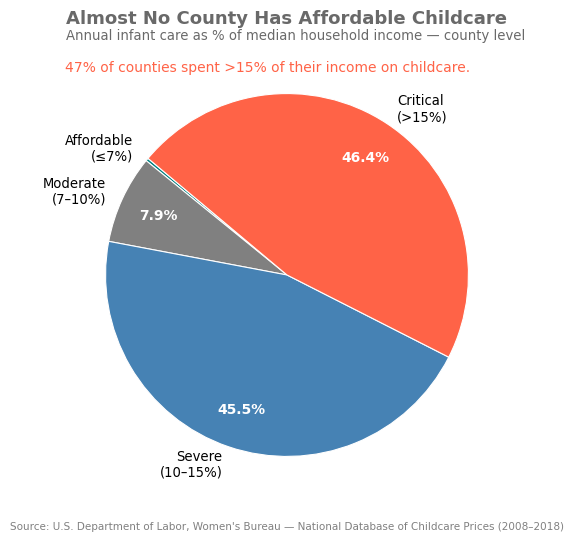

In [51]:
# Pie Chart 

# Dataframe
df_pie = df.dropna(subset=['infant_pct_income']).copy()

bins   = [0, 7, 10, 15, 100]
labels_cat = ['Affordable\n(≤7%)', 'Moderate\n(7–10%)',
              'Severe\n(10–15%)', 'Critical\n(>15%)']
df_pie['burden_cat'] = pd.cut(df_pie['infant_pct_income'],
                               bins=bins, labels=labels_cat)

sizes      = df_pie['burden_cat'].value_counts().reindex(labels_cat)
colors_pie = [TEAL, GRAY, SBLUE, TOMATO]
explode    = (0.0, 0.0, 0.0, 0.0)

# Chart
fig, ax = plt.subplots(figsize=(7, 5.5))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

wedges, texts, autotexts = ax.pie(
    sizes, labels=labels_cat, colors=colors_pie, explode=explode,
    autopct=lambda p: f'{p:.1f}%' if p > 1 else '',
    startangle=140,
    textprops={'fontsize': 9.5},
    pctdistance=0.78,
    wedgeprops={'edgecolor': 'white', 'linewidth': 0.8})

for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight('bold')
    at.set_color('white')

ax.set_title('Almost No County Has Affordable Childcare',
             fontsize=13, fontweight='bold', color=DARK, loc='center', pad=18)
ax.text(0.52, 1.02,
        'Annual infant care as % of median household income — county level',
        ha='center', transform=ax.transAxes, fontsize=9.5, color=DARK)

ax.text(0.01, 0.95,
        '47% of counties spent >15% of their income on childcare.',
        transform=ax.transAxes, fontsize=10, color=TOMATO)

ax.text(0.5, -0.06, SOURCE, fontsize=7.5, color=GRAY,
        ha='center', transform=ax.transAxes)

plt.tight_layout()
plt.show()

Four out of five counties have families spending more than 10% of their entire household income on infant care alone.

Only 0.2% of counties have affordable childcare, <= 7% of thier income. 46.4% of counties spent >15% of thier income on childcare.

#### P4 - Horizontal Stacked Bar 

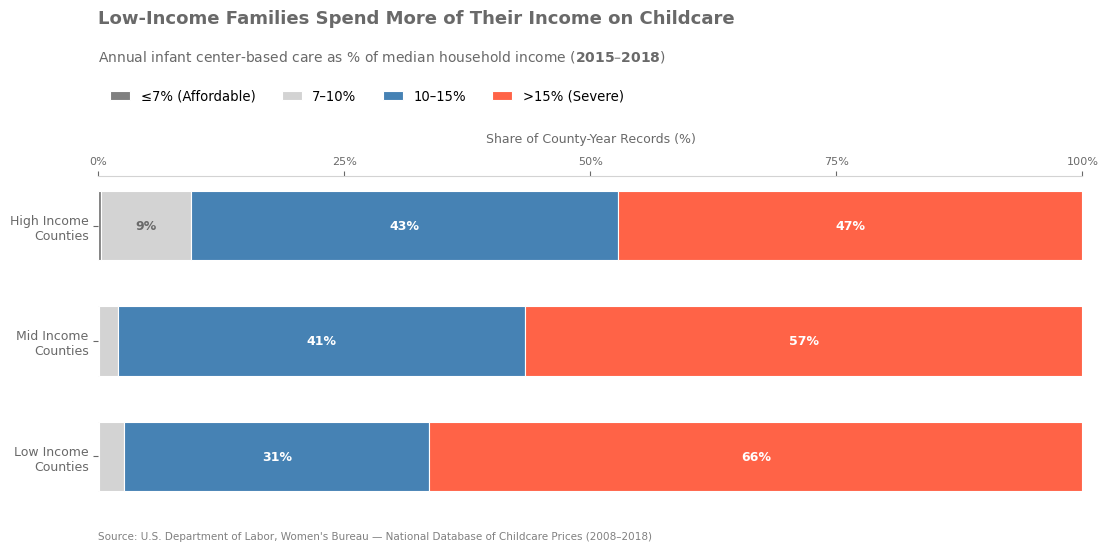

In [52]:
# Data Prep (2015-2018)
df_filtered = df[df['StudyYear'].between(2015, 2018)].copy()

df_p3 = df_filtered.dropna(subset=['infant_pct_income', 'MHI_2018']).copy()
df_p3['income_tier'] = pd.qcut(
    df_p3['MHI_2018'], q=3, 
    labels=['Low Income\nCounties', 'Mid Income\nCounties', 'High Income\nCounties'])

bins   = [0, 7, 10, 15, 100]
labels_b = ['≤7% (Affordable)', '7–10%', '10–15%', '>15% (Severe)']
colors_bar = [GRAY, LIGHT, SBLUE, TOMATO] 

df_p3['burden_cat'] = pd.cut(df_p3['infant_pct_income'], bins=bins, labels=labels_b)

pivot = (df_p3.groupby(['income_tier', 'burden_cat'], observed=True)
                .size()
                .unstack(fill_value=0))
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

# Chart 
fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
style_ax(ax)

lefts = np.zeros(len(pivot_pct))
for col, color in zip(pivot_pct.columns, colors_bar):
    vals = pivot_pct[col].values
    ax.barh(pivot_pct.index, vals, left=lefts, 
            color=color, height=0.6, 
            edgecolor='white', linewidth=0.8, label=col)
    for j, (v, l) in enumerate(zip(vals, lefts)):
        if v > 5:
            ax.text(l + v / 2, j, f'{v:.0f}%', 
                    ha='center', va='center', 
                    fontsize=9, color='white' if color != LIGHT else DARK, 
                    fontweight='bold')
    lefts += vals

ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
# Only top spine stays visible as the "header" line
ax.spines['top'].set_visible(True)
ax.spines['top'].set_color(LIGHT)

# Formatting
ax.set_xlim(0, 100)
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(['0%', '25%', '50%', '75%', '100%'], fontsize=8, color=DARK)

# Increased labelpad to move 'Share of County-Year Records' closer to the axis line
ax.set_xlabel('Share of County-Year Records (%)', fontsize=9, color=DARK, labelpad=10)

ax.set_title('Low-Income Families Spend More of Their Income on Childcare', 
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=110)

ax.text(0, 1.35, r'Annual infant center-based care as % of median household income ($\mathbf{2015}$–$\mathbf{2018}$)', 
        transform=ax.transAxes, fontsize=10, color=DARK)

ax.legend(loc='upper left', bbox_to_anchor=(0, 1.30), 
          fontsize=9.5, frameon=False, ncol=4, handlelength=1.5)

ax.text(0, -0.10, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)

plt.subplots_adjust(left=0.14, right=0.96, top=0.70, bottom=0.15)

plt.show()

Between 2015 and 2018, In low-income counties, 66% of families spent more than 15% of their household income on infant care alone. In high-income counties, 47% of families pent more than 15% of their household income on infant care. Unaffordable childcare is not just a low-income issue, it affects the majority of American families regardless of how much they earn.

From 2015 to 2018, 66% of low-income counties faced severe childcare cost burden, families spending more than 15% of household income on one child's care.

#### P5 Heatmap Chart

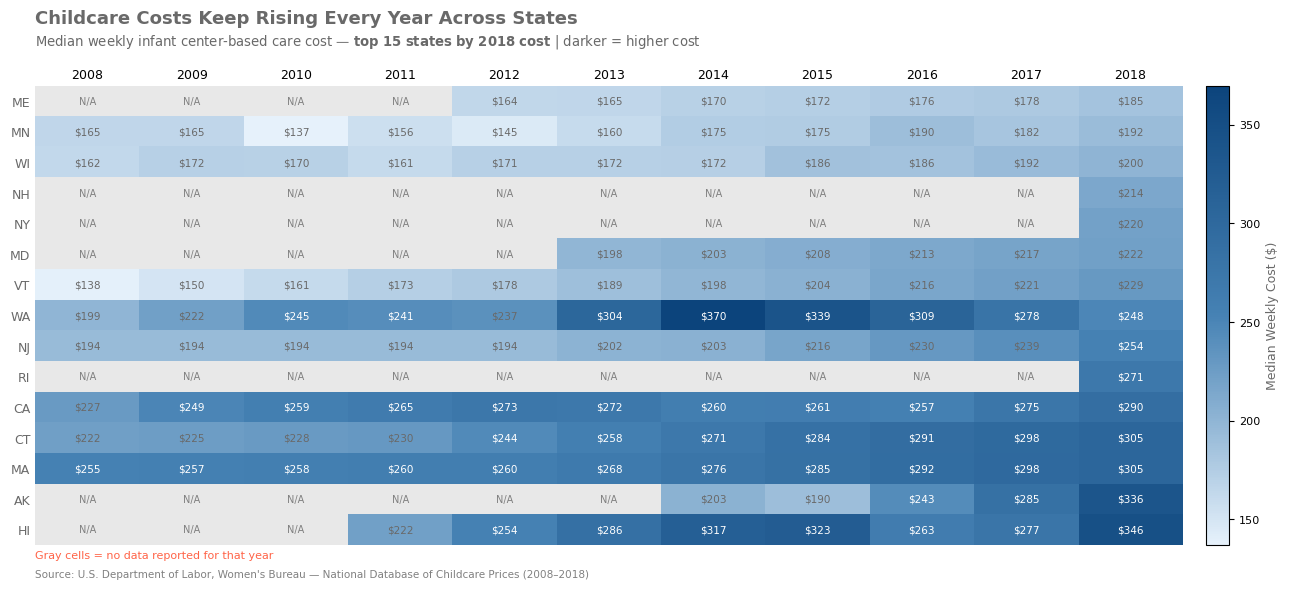

In [53]:
pivot_hm = (df.groupby(['State_Abbreviation', 'StudyYear'])['MCInfant']
              .median()
              .unstack('StudyYear'))
 
# Top 15 states by 2018 infant care cost
top15 = (pivot_hm[2018]
           .dropna()
           .sort_values(ascending=False)
           .head(15)
           .index)
pivot_hm = pivot_hm.loc[top15]
 
pivot_hm = pivot_hm.sort_values(2018, ascending=True)
 
# Chart
fig, ax = plt.subplots(figsize=(13, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
 
# Custom blue colormap — gray for missing (NaN) cells
cmap = mcolors.LinearSegmentedColormap.from_list(
    'childcare', ['#E6F1FB', SBLUE, '#0C447C'])
cmap.set_bad(color='#E8E8E8')   # light gray for NaN
 
# Mask NaN so they render as gray
masked = np.ma.masked_invalid(pivot_hm.values)
 
im = ax.imshow(masked, aspect='auto', cmap=cmap,
               interpolation='nearest')
 
# X axis — years
ax.set_xticks(range(len(pivot_hm.columns)))
ax.set_xticklabels(pivot_hm.columns, fontsize=9)
 
# Y axis — state abbreviations
ax.set_yticks(range(len(pivot_hm.index)))
ax.set_yticklabels(pivot_hm.index, fontsize=9)
ax.tick_params(axis='both', length=0)
 
# Bold ONLY 2018 on x-axis
fig.canvas.draw()
for label in ax.get_xticklabels():
    if label.get_text() == '2018':
        label.set_color(BLACK)
        label.set_fontweight('bold')
        label.set_fontsize(10)
    else:
        label.set_color(DARK)
        label.set_fontweight('normal')
        label.set_fontsize(9)
 
for label in ax.get_yticklabels():
    label.set_color(DARK)
    label.set_fontweight('normal')
    label.set_fontsize(9)
 
for i in range(pivot_hm.shape[0]):
    for j in range(pivot_hm.shape[1]):
        val = pivot_hm.values[i, j]
        if np.isnan(val):
            ax.text(j, i, 'N/A',
                    ha='center', va='center',
                    fontsize=7, color=GRAY)
        else:
            threshold = masked.compressed().max() * 0.65
            color = 'white' if val > threshold else DARK
            ax.text(j, i, '${:.0f}'.format(val),
                    ha='center', va='center',
                    fontsize=7.5, color=color)
 
# Colorbar
cbar = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.02)
cbar.set_label('Median Weekly Cost ($)', fontsize=9, color=DARK)
cbar.ax.tick_params(labelsize=8)
 
# X axis on top
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()
ax.tick_params(axis='x', length=0, labelsize=9)
 
ax.text(0, -0.03,'Gray cells = no data reported for that year',
        fontsize=8, color=TOMATO, transform=ax.transAxes)
 
ax.set_title('Childcare Costs Keep Rising Every Year Across States',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=45)
ax.text(0, 1.09,
        'Median weekly infant center-based care cost — $\mathbf{top\ 15\ states\ by\ 2018\ cost}$ | darker = higher cost',
        transform=ax.transAxes, fontsize=9.5, color=DARK)
 
ax.text(0, -0.07, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)
 
plt.tight_layout()

plt.show()

Childcare costs are getting more expensive across almost every state and every year. Some states like New York ($220/week), New Hampshire ($214/week), Wisconsin ($200/week), and Minnesota ($192/week) are consistently the  most expensive. 
Employers with offices or employees in these states should prioritize benefits there first.

By 2018, states like New York and New Hampshire exceeded $200/week for infant care, employers in these states may face the highest retention risk.

#### P6- Difference Chart

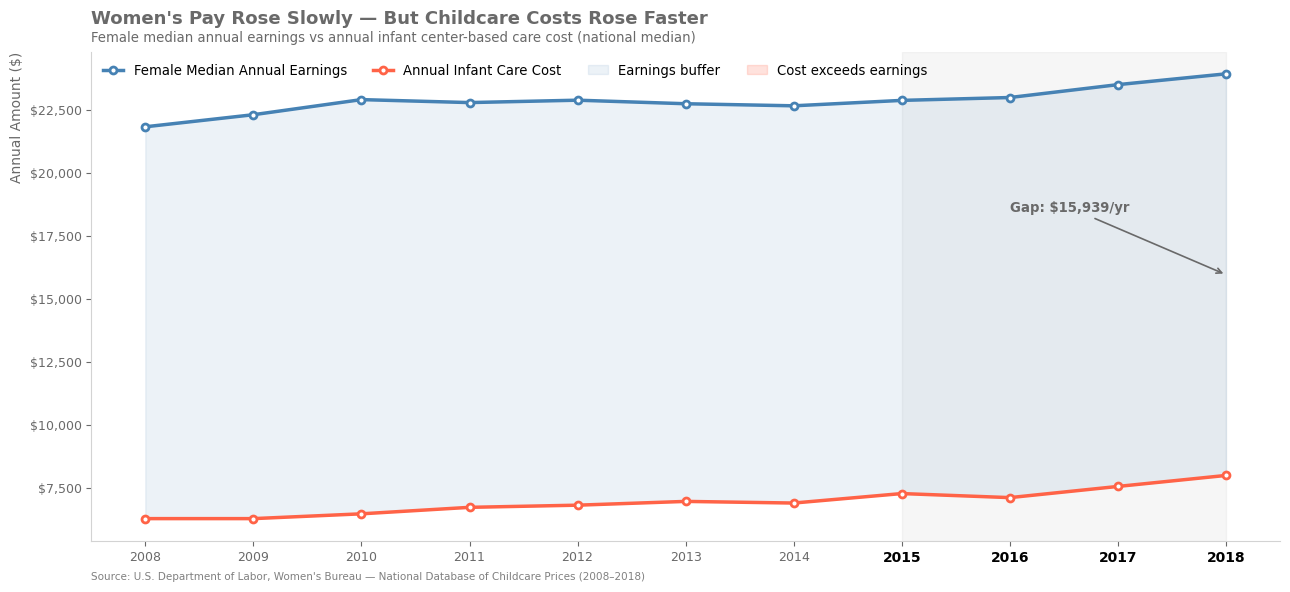

In [54]:
# Difference Chart 

# Data 
diff_df = (df.groupby('StudyYear')
             .agg(fme =('FME_2018',        'median'),
                  care=('annual_mc_infant', 'median'))
             .reset_index())

# Chart
fig, ax = plt.subplots(figsize=(13, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
style_ax(ax)

# Lines
ax.plot(diff_df['StudyYear'], diff_df['fme'],
        color=SBLUE, linewidth=2.5,
        marker='o', markersize=5,
        markerfacecolor='white', markeredgecolor=SBLUE, markeredgewidth=2,
        label='Female Median Annual Earnings')

ax.plot(diff_df['StudyYear'], diff_df['care'],
        color=TOMATO, linewidth=2.5,
        marker='o', markersize=5,
        markerfacecolor='white', markeredgecolor=TOMATO, markeredgewidth=2,
        label='Annual Infant Care Cost')

# Fill gap
ax.fill_between(diff_df['StudyYear'], diff_df['care'], diff_df['fme'],
                where=diff_df['fme'] >= diff_df['care'],
                alpha=0.10, color=SBLUE, label='Earnings buffer')
ax.fill_between(diff_df['StudyYear'], diff_df['care'], diff_df['fme'],
                where=diff_df['fme'] < diff_df['care'],
                alpha=0.18, color=TOMATO, label='Cost exceeds earnings')

# Shade 2015-2018
ax.axvspan(2015, 2018, alpha=0.06, color=DARK, zorder=0)

# Annotate gap at 2018
last = diff_df[diff_df['StudyYear'] == 2018].iloc[0]
gap  = last['fme'] - last['care']
ax.annotate(f'Gap: ${gap:,.0f}/yr',
            xy=(2018, (last['fme'] + last['care']) / 2),
            xytext=(2016, (last['fme'] + last['care']) / 2 + 2500),
            fontsize=9.5, color=DARK, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=DARK, lw=1.2))

ax.set_xticks(diff_df['StudyYear'])
ax.set_ylabel('Annual Amount ($)', fontsize=10, color=DARK, loc="top")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

# Bold 2015-2018 x-tick labels
fig.canvas.draw()
for label in ax.get_xticklabels():
    txt = label.get_text()
    if txt.isdigit() and int(txt) >= 2015:
        label.set_color(BLACK)
        label.set_fontweight('bold')
        label.set_fontsize(10)
    else:
        label.set_color(DARK)
        label.set_fontweight('normal')
        label.set_fontsize(9)

ax.set_title("Women's Pay Rose Slowly — But Childcare Costs Rose Faster",
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=20)
ax.text(0, 1.02,
        'Female median annual earnings vs annual infant center-based care cost (national median)',
        transform=ax.transAxes, fontsize=9.5, color=DARK)

ax.legend(loc='upper left', bbox_to_anchor=(0, 1), fontsize=9.5, frameon=False, ncol=4, handlelength=1.5)

ax.text(0, -0.08, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)

plt.tight_layout()
plt.show()

Between 2008 and 2018, female median earnings grew by only $2,102, from $21,824 to $23,926. 

Over the same period childcare costs grew by $1,714, from  $6,273 to $7,987.

Women earned $2,102 more, but childcare cost $1,714 more in 10 years.

#### P7 Baseline Chart

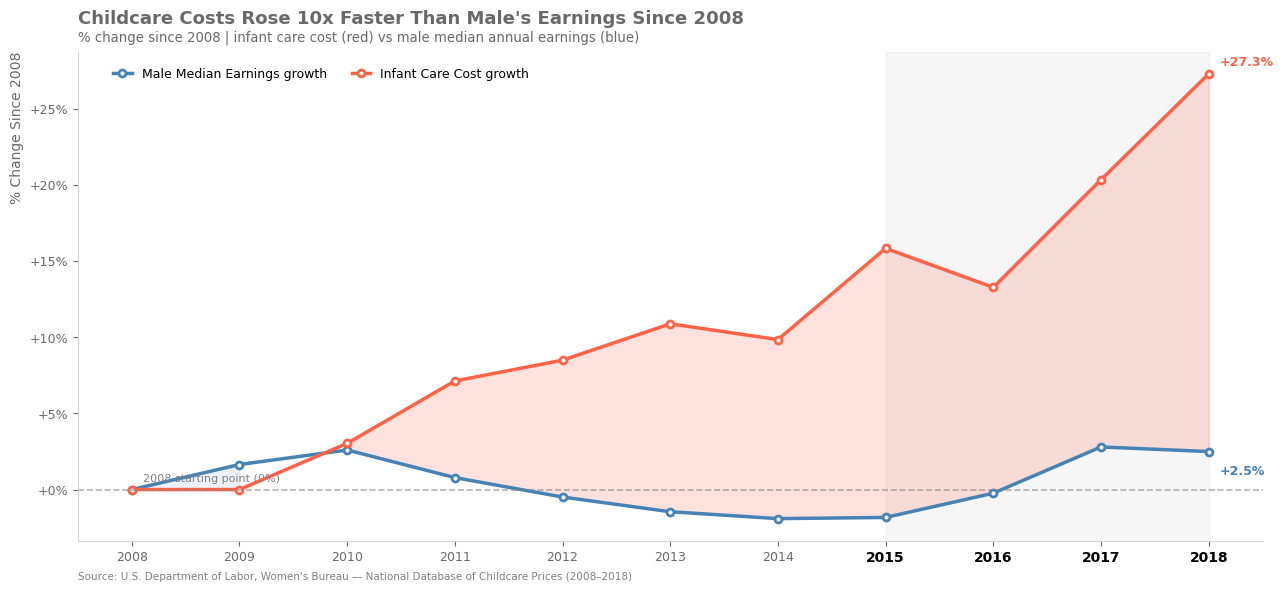

In [56]:
# Baseline Chart

# 2008 baseline values first
base_mme  = diff_df.loc[diff_df['StudyYear'] == 2008, 'mme'].values[0]
base_care = diff_df.loc[diff_df['StudyYear'] == 2008, 'care'].values[0]

# Date
diff_df = (df.groupby('StudyYear')
             .agg(mme =('MME_2018',        'median'),
                  care=('annual_mc_infant', 'median'))
             .reset_index())

# % change from 2008 baseline
diff_df['mme_pct']  = (diff_df['mme']  / base_mme  - 1) * 100
diff_df['care_pct'] = (diff_df['care'] / base_care - 1) * 100

# Chart
fig, ax = plt.subplots(figsize=(13, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
style_ax(ax)

ax.plot(diff_df['StudyYear'], diff_df['mme_pct'],
        color=SBLUE, linewidth=2.5,
        marker='o', markersize=5,
        markerfacecolor='white', markeredgecolor=SBLUE, markeredgewidth=2,
        label='Male Median Earnings growth')

ax.plot(diff_df['StudyYear'], diff_df['care_pct'],
        color=TOMATO, linewidth=2.5,
        marker='o', markersize=5,
        markerfacecolor='white', markeredgecolor=TOMATO, markeredgewidth=2,
        label='Infant Care Cost growth')

# Fill between
ax.fill_between(diff_df['StudyYear'], diff_df['care_pct'], diff_df['mme_pct'],
                where=diff_df['mme_pct'] >= diff_df['care_pct'],
                alpha=0.10, color=SBLUE)
ax.fill_between(diff_df['StudyYear'], diff_df['care_pct'], diff_df['mme_pct'],
                where=diff_df['mme_pct'] < diff_df['care_pct'],
                alpha=0.18, color=TOMATO)

# Baseline at 0%
ax.axhline(0, color=GRAY, linewidth=1.2, linestyle='--', alpha=0.6)
ax.text(2008.1, 0.5, '2008 starting point (0%)', fontsize=8, color=GRAY)

# Shade 2015-2018
ax.axvspan(2015, 2018, alpha=0.06, color=DARK, zorder=0)

# Annotate 2018 values
last = diff_df[diff_df['StudyYear'] == 2018].iloc[0]
ax.text(2018.1, last['care_pct'] + 0.5, f"+{last['care_pct']:.1f}%",
        fontsize=9, color=TOMATO, fontweight='bold')
ax.text(2018.1, last['mme_pct'] - 1.5, f"+{last['mme_pct']:.1f}%",
        fontsize=9, color=SBLUE, fontweight='bold')

ax.set_xticks(diff_df['StudyYear'])
ax.set_ylabel('% Change Since 2008', fontsize=10, color=DARK, loc = "top")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:+.0f}%'))

# Bold 2015-2018 x-tick labels
fig.canvas.draw()
for label in ax.get_xticklabels():
    txt = label.get_text()
    if txt.isdigit() and int(txt) >= 2015:
        label.set_color(BLACK); label.set_fontweight('bold'); label.set_fontsize(10)
    else:
        label.set_color(DARK); label.set_fontweight('normal'); label.set_fontsize(9)

ax.set_title("Childcare Costs Rose 10x Faster Than Male's Earnings Since 2008",
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=20)
ax.text(0, 1.02,
        '% change since 2008 | infant care cost (red) vs male median annual earnings (blue)',
        transform=ax.transAxes, fontsize=9.5, color=DARK)

ax.legend(loc='upper left', fontsize=9, frameon=False, bbox_to_anchor=(0.02, 0.99),
         ncol=2, handlelength=1.5)

ax.text(0, -0.08, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)

plt.tight_layout()
plt.show()



Since 2008 childcare costs have risen more than ten times faster than male median earnings,  +27.3% versus just +2.5% in 10 years.

This means the financial gap between what families earn and what they pay for childcare has been increasing consistently for over a decadeChildcare Costs Rose 10x Faster Than Earnings Since 2008.

Childcare costs rose 27% since 2008, and male earnings grew just 2.5%

#### P8 - Scatter Chart

/var/folders/5m/6p6yb9yd0y58fhdzlnmkgglr0000gn/T/ipykernel_26717/851910097.py:46: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', fontsize=9, frameon=False)


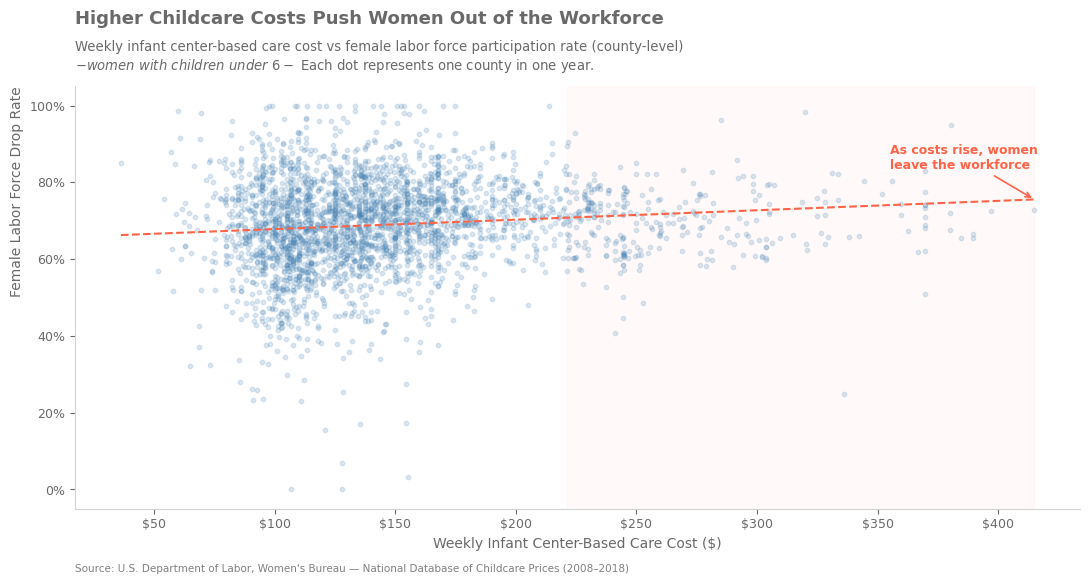

In [57]:
# Scatter Plot 

# Data 
plot_df = (df[['MCInfant', 'FLFPR_20to64_Under6', 'State_Name']]
             .dropna()
             .sample(min(3000, len(df)), random_state=42))

# Chart 
fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
style_ax(ax)

# Scatter dots
ax.scatter(plot_df['MCInfant'], plot_df['FLFPR_20to64_Under6'],
           alpha=0.18, s=10, color=SBLUE, zorder=2)

# Trend line
z      = np.polyfit(plot_df['MCInfant'], plot_df['FLFPR_20to64_Under6'], 1)
p      = np.poly1d(z)
x_line = np.linspace(plot_df['MCInfant'].min(), plot_df['MCInfant'].max(), 200)
ax.plot(x_line, p(x_line), color=TOMATO, linewidth=1.5, linestyle="--", zorder=3)

ax.annotate(f'As costs rise, women\nleave the workforce',
            xy=(x_line[-1], p(x_line[-1])),
            xytext=(x_line[-1] - 60, p(x_line[-1]) + 8),
            fontsize=9, color=TOMATO, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=TOMATO, lw=1.2))

# Shade high-cost zone
ax.axvspan(plot_df['MCInfant'].quantile(0.90),
           plot_df['MCInfant'].max(),
           alpha=0.03, color=TOMATO, zorder=0)

# Axes
ax.set_xlabel('Weekly Infant Center-Based Care Cost ($)', fontsize=10, color=DARK)
ax.set_ylabel('Female Labor Force Drop Rate',
              fontsize=10, color=DARK, loc="top")

ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.tick_params(axis='both', labelsize=9)

# Bold 2015-2018 pattern not applicable here — no year axis
# Legend
ax.legend(loc='upper right', fontsize=9, frameon=False)

ax.set_title('Higher Childcare Costs Push Women Out of the Workforce',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=45)

ax.text(0, 1.04,
        r'Weekly infant center-based care cost vs female labor force participation rate (county-level)' + '\n' +
        r'$\mathit{-women\ with\ children\ under\ 6-}$ Each dot represents one county in one year.',
        transform=ax.transAxes, fontsize=9.5, color=DARK)

# ax.text(0, 1.35, r'Annual infant center-based care as % of median household income ($\mathbf{2015}$–$\mathbf{2018}$)', transform=ax.transAxes, fontsize=10, color=DARK)


ax.text(0, -0.15, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)

plt.tight_layout()
plt.show()



Single mothers are paying more than double what two-parent households pay, 33% of their income versus 16% in 2018. 
Both groups paying more each year between 2008 and 2018, but single mothers carry an extra burden.

Employer should look at the single mother wages and child care benefits.

By 2018 single mothers spent 33% of their income on childcare, it is more than double the burden of two-parent households and five times the HHS affordable threshold of 7%.


#### I9- Waffle or Square Pie Chart

/var/folders/5m/6p6yb9yd0y58fhdzlnmkgglr0000gn/T/ipykernel_26717/1942455659.py:40: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(plt.Rectangle(


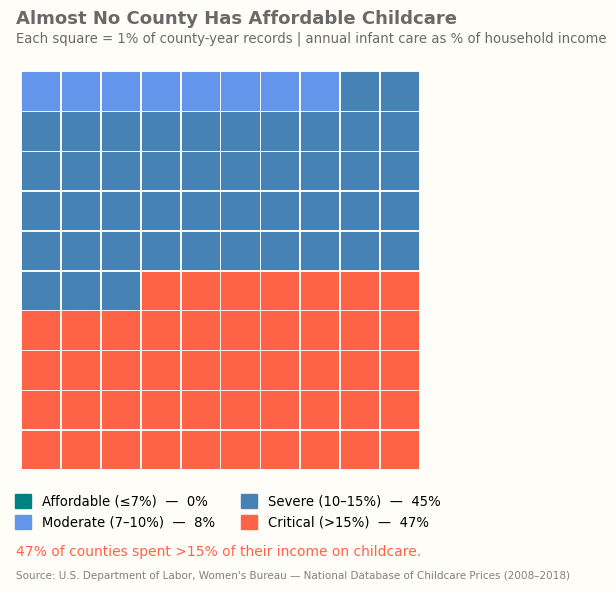

In [85]:
# Waffle Chart 

#  Data 
df_pie = df.dropna(subset=['infant_pct_income']).copy()

bins       = [0, 7, 10, 15, 100]
labels_cat = ['Affordable (≤7%)', 'Moderate (7–10%)',
              'Severe (10–15%)',   'Critical (>15%)']
df_pie['burden_cat'] = pd.cut(df_pie['infant_pct_income'],
                               bins=bins, labels=labels_cat)

sizes      = df_pie['burden_cat'].value_counts().reindex(labels_cat)
pcts       = (sizes / sizes.sum() * 100).round(0).astype(int)

# Force total = 100
diff = 100 - pcts.sum()
pcts.iloc[pcts.argmax()] += diff

colors_waffle = [TEAL, CBLUE, SBLUE, TOMATO]

# Build 10x10 grid
grid = []
for label, count, color in zip(labels_cat, pcts, colors_waffle):
    grid.extend([color] * count)
grid = grid[:100]   # safety trim

# Reshape to 10x10
grid_arr = np.array(grid).reshape(10, 10)

# Chart 
fig, ax = plt.subplots(figsize=(7, 6))
fig.patch.set_facecolor('#fffdf7') # white
ax.set_facecolor('white')
ax.set_aspect('equal')
ax.axis('off')

for i in range(10):
    for j in range(10):
        color = grid_arr[9 - i][j]   # flip so row 0 is bottom
        ax.add_patch(plt.Rectangle(
            (j * 1.1, i * 1.1), 1, 1,
            color=color, linewidth=1.5,
            edgecolor='white'))

# Legend with percentages
legend_patches = [
    mpatches.Patch(color=c, label=f'{l}  —  {p}%')
    for c, l, p in zip(colors_waffle, labels_cat, pcts)]

ax.legend(handles=legend_patches,
          loc='lower center', bbox_to_anchor=(0.5, -0.04),
          fontsize=9.5, frameon=False, ncol=2,
          handlelength=1.2, handleheight=1.2)

ax.set_xlim(-0.2, 11.5)
ax.set_ylim(-1.5, 11.5)

ax.set_title('Almost No County Has Affordable Childcare',
             fontsize=13, fontweight='bold', color=DARK,
             loc='left', pad=20)
ax.text(0, 1.02,
        'Each square = 1% of county-year records | annual infant care as % of household income',
        transform=ax.transAxes, fontsize=9.5, color=DARK)

ax.text(0, -0.07,
        '47% of counties spent >15% of their income on childcare.',
        transform=ax.transAxes, fontsize=10, color=TOMATO)

ax.text(0, -0.12, SOURCE, fontsize=7.5, color=GRAY,
        transform=ax.transAxes)

plt.tight_layout()
plt.show()

Four out of five counties have families spending more than 10% of their entire household income on infant care alone.

Only 0.2% of counties have affordable childcare, <= 7% of thier income.

#### I 10 Line Chart

<function matplotlib.pyplot.show(close=None, block=None)>

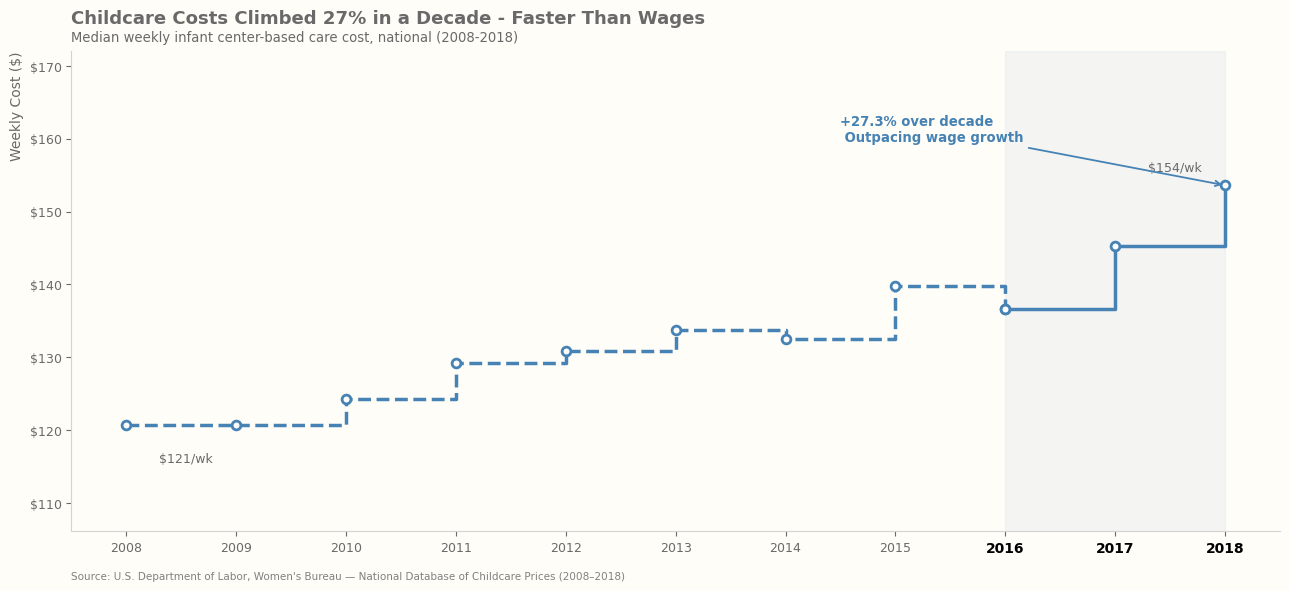

In [87]:
# Line Chart

# Data 
yearly = (df.groupby('StudyYear')['MCInfant']
            .median()
            .reset_index()
            .rename(columns={'MCInfant': 'median_cost'}))

pct_rise = ((yearly.iloc[-1]['median_cost'] - yearly.iloc[0]['median_cost'])
            / yearly.iloc[0]['median_cost'] * 100)

# Masks — 2015 
mask_pre  = yearly['StudyYear'] <= 2016
mask_last = yearly['StudyYear'] >= 2016

# Chart
fig, ax = plt.subplots(figsize=(13, 6))
fig.patch.set_facecolor('#fffdf7') # white
ax.set_facecolor('#fffdf7') # white
style_ax(ax)

# Shade 2016-2018
ax.axvspan(2016, 2018, alpha=0.06, color=SBLUE, zorder=0)

# Dashed step 2008-2015
ax.step(yearly[mask_pre]['StudyYear'], yearly[mask_pre]['median_cost'],
        where='post', color=SBLUE, linewidth=2.5, linestyle='--')

# Solid step 2015-2018
ax.step(yearly[mask_last]['StudyYear'], yearly[mask_last]['median_cost'],
        where='post', color=SBLUE, linewidth=2.5, linestyle='-')

# Dots at each year
ax.scatter(yearly[mask_pre]['StudyYear'], yearly[mask_pre]['median_cost'],
           s=40, color='white', edgecolors=SBLUE, linewidth=2, zorder=3)
ax.scatter(yearly[mask_last]['StudyYear'], yearly[mask_last]['median_cost'],
           s=40, color='white', edgecolors=SBLUE, linewidth=2, zorder=3)

# Annotate first and last
ax.annotate(f"${yearly.iloc[0]['median_cost']:.0f}/wk",
            xy=(yearly.iloc[0]['StudyYear'], yearly.iloc[0]['median_cost']),
            xytext=(2008.3, yearly.iloc[0]['median_cost'] - 5),
            fontsize=9, color=DARK)
ax.annotate(f"${yearly.iloc[-1]['median_cost']:.0f}/wk",
            xy=(yearly.iloc[-1]['StudyYear'], yearly.iloc[-1]['median_cost']),
            xytext=(2017.3, yearly.iloc[-1]['median_cost'] + 2),
            fontsize=9, color=DARK)

# Key callout
peak_yr  = yearly.loc[yearly['median_cost'].idxmax(), 'StudyYear']
peak_val = yearly['median_cost'].max()
ax.annotate(f'+{pct_rise:.1f}% over decade\n Outpacing wage growth',
            xy=(peak_yr, peak_val),
            xytext=(2014.5, peak_val + 6),
            fontsize=9.5, color=SBLUE, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=SBLUE, lw=1.3))

# Titles
ax.set_title('Childcare Costs Climbed 27% in a Decade - Faster Than Wages',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=20)
ax.text(0, 1.02,
        'Median weekly infant center-based care cost, national (2008-2018)',
        transform=ax.transAxes, fontsize=9.5, color=DARK)

ax.set_ylabel('Weekly Cost ($)', fontsize=10, color=DARK, loc='top')

ax.set_xticks(yearly['StudyYear'])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}'))
ax.set_ylim(yearly['median_cost'].min() * 0.88, yearly['median_cost'].max() * 1.12)

# Bold 2015-2018 x-tick labels, normal dimgray for 2008-2014
fig.canvas.draw()
for label in ax.get_xticklabels():
    txt = label.get_text()
    if txt.isdigit():
        yr = int(txt)
        if yr >= 2016:
            label.set_color(BLACK)
            label.set_fontweight('bold')
            label.set_fontsize(10)
        else:
            label.set_color(DARK)
            label.set_fontweight('normal')
            label.set_fontsize(9)

ax.text(0, -0.1, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)

plt.tight_layout()
plt.show




Childcare costs have been rising consistently for over a decade, and this is not a temporary problem but a long-term trend. Childcare costs grew 27.7% and the affordability gap widens every single year, and employer have not started thinnking about it.

Childcare costs climbed step by step every year from $121/week in 2008 to $154/week in 2018.

+27.7% in 10 years — childcare costs are rising faster than wages

#### I 11 -Histogram Chart

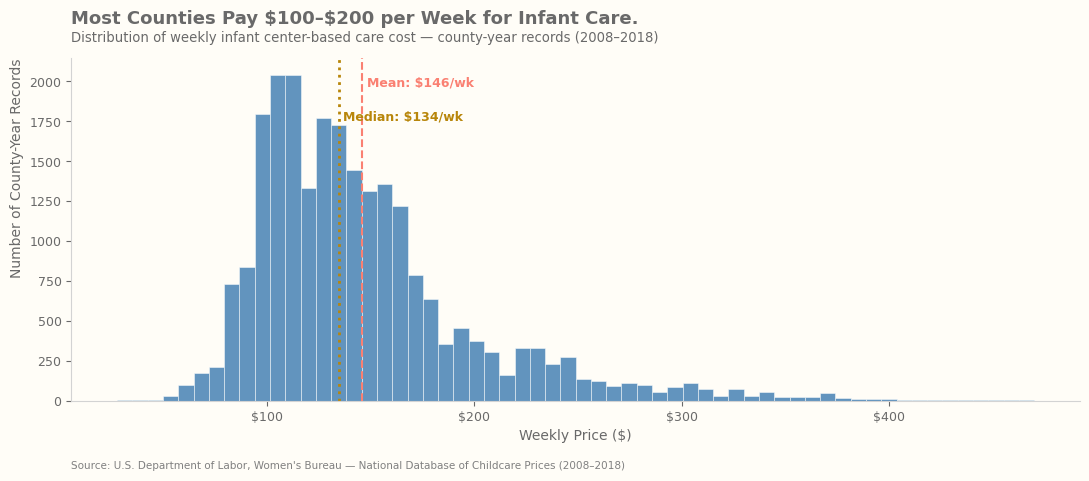

In [88]:
# Histogram 

#  Data 
data = df['MCInfant'].dropna()

# Chart 
fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor('#fffdf7') # white
ax.set_facecolor('#fffdf7') # white
style_ax(ax)

ax.hist(data, bins=60, color=SBLUE, edgecolor='white',
        linewidth=0.4, alpha=0.85)

# Mean and median lines
ax.axvline(data.mean(),   color=SALMON, linewidth=1.5, linestyle='--')
ax.axvline(data.median(), color=AMBER,  linewidth=2, linestyle=':')

# Inline annotations instead of legend
ax.text(data.mean()   + 2, ax.get_ylim()[1] * 0.92,
        f'Mean: ${data.mean():.0f}/wk',
        fontsize=9, color=SALMON, fontweight='bold')
ax.text(data.median() + 2, ax.get_ylim()[1] * 0.82,
        f'Median: ${data.median():.0f}/wk',
        fontsize=9, color=AMBER, fontweight='bold')

ax.set_xlabel('Weekly Price ($)', fontsize=10, color=DARK)
ax.set_ylabel('Number of County-Year Records', fontsize=10, color=DARK, loc='top')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}'))
ax.tick_params(axis='both', labelsize=9)

ax.set_title('Most Counties Pay \$100–\$200 per Week for Infant Care.',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=25)
ax.text(0, 1.05,
        'Distribution of weekly infant center-based care cost — county-year records (2008–2018)',
        transform=ax.transAxes, fontsize=9.5, color=DARK)

ax.text(0, -0.2, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)

plt.tight_layout()
plt.show()


A significant number of counties charge above $200, with some reaching as high as $470 per week. 
Employers with offices in high-cost urban areas are facing a very different childcare reality than the national average suggests. 


Most counties charge $100–$200/week for infant care, some reach as high as $470/week, it is nearly four times the national median.

#### I 12 - Barbell Chart

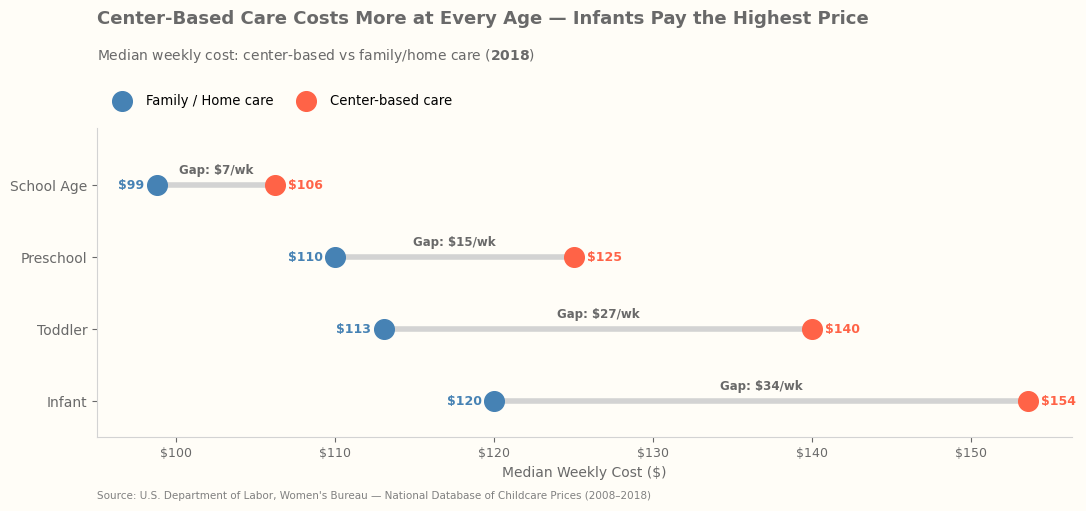

In [89]:
# Define column lists first
mc_cols   = ['MCInfant', 'MCToddler', 'MCPreschool', 'MCSA']
mfcc_cols = ['MFCCInfant', 'MFCCToddler', 'MFCCPreschool', 'MFCCSA']
age_groups = ['Infant', 'Toddler', 'Preschool', 'School Age']

# Data Prep (2015-2018)
df_filtered = df[df['StudyYear'] == 2018]
mc_med   = [df_filtered[c].median() for c in mc_cols]
mfcc_med = [df_filtered[c].median() for c in mfcc_cols]

fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor('#fffdf7') # white
ax.set_facecolor('#fffdf7') # white
style_ax(ax)

y = np.arange(len(age_groups))

# Connecting line
for i in range(len(age_groups)):
    ax.hlines(y[i], mfcc_med[i], mc_med[i], colors=LIGHT, linewidth=4, zorder=1)

# Dots
ax.scatter(mfcc_med, y, color=SBLUE,  s=200, zorder=3, label='Family / Home care')
ax.scatter(mc_med,   y, color=TOMATO, s=200, zorder=3, label='Center-based care')

# Labels on dots
for i, (mc, mfcc) in enumerate(zip(mc_med, mfcc_med)):
    ax.text(mc + 0.8, y[i], f'${mc:.0f}', fontsize=9, color=TOMATO, 
            fontweight='bold', va='center', ha='left')
    ax.text(mfcc - 0.8, y[i], f'${mfcc:.0f}', fontsize=9, color=SBLUE, 
            fontweight='bold', va='center', ha='right')
    
    # Gap annotation
    ax.text((mc + mfcc) / 2, y[i] + 0.12, f'Gap: ${mc - mfcc:.0f}/wk',
            fontsize=8.5, color=DARK, ha='center', va='bottom', fontweight='bold')

# Formatting
ax.set_yticks(y)
ax.set_yticklabels(age_groups, fontsize=10, color=DARK)

ax.set_xlim(left=95) 

ax.set_xlabel('Median Weekly Cost ($)', fontsize=10, color=DARK)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}'))

ax.set_ylim(-0.5, len(age_groups) - 0.2) 

# Legend
ax.legend(loc='upper left', bbox_to_anchor=(0, 1.15), ncol=2, 
          fontsize=9.5, frameon=False, columnspacing=1.5)

# Subtitle with bolded years
ax.text(0, 1.22, r'Median weekly cost: center-based vs family/home care ($\mathbf{2018}$)',
        transform=ax.transAxes, fontsize=10, color=DARK)

# Title
ax.set_title('Center-Based Care Costs More at Every Age — Infants Pay the Highest Price',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=75)

ax.text(0, -0.2, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)

plt.tight_layout(rect=[0, 0, 1, 0.92]) 
plt.show()

Center-based care costs more than family home-based care at every single age group in 2018, with infants carrying the highest price of all at $154/week.

Female employees returning from maternity leave face the financial shock of their career — USD 154/week for infant center care alone, nearly USD 8,000 per year. 

If employers want to make a real difference, infant care is where benefits should be focused. It is the most expensive stage where female employees are most financially vulnerable.

"Infant center care costs USD 154/week in 2018 — USD 1,768/year more than home-based care"



#### I 13 - Stacked Area Chart

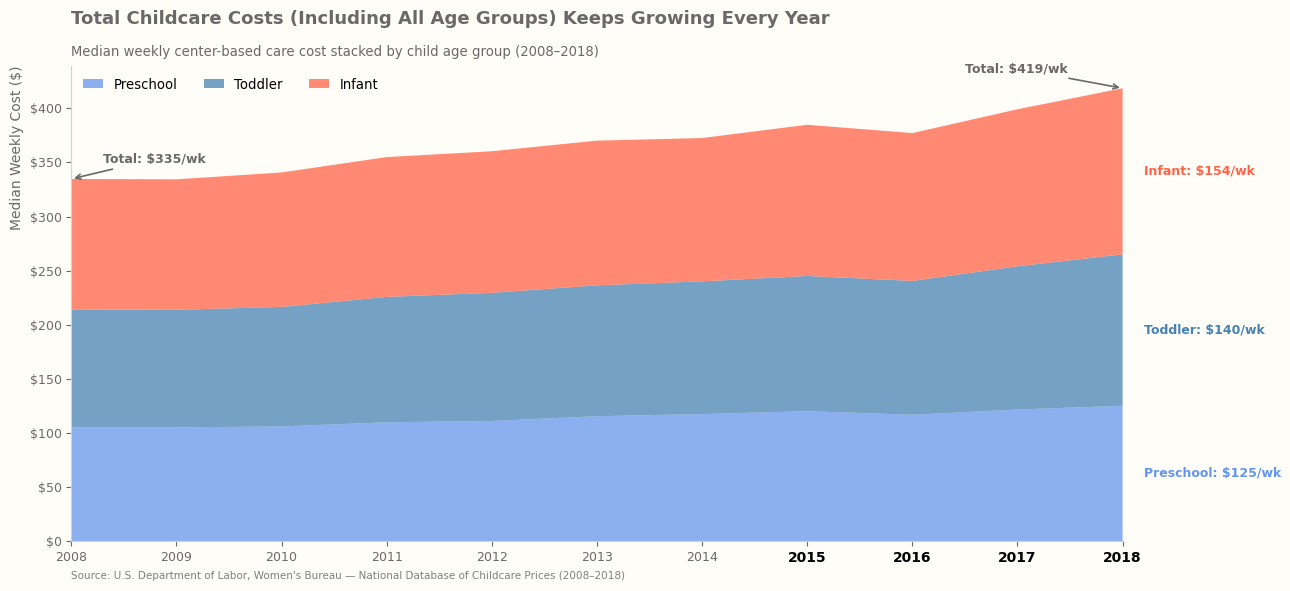

In [90]:
area_df = (df.groupby('StudyYear')[['MCInfant', 'MCToddler', 'MCPreschool']]
             .median()
             .reset_index())
area_df.columns = ['Year', 'Infant', 'Toddler', 'Preschool']
 
# Chart
fig, ax = plt.subplots(figsize=(13, 6))
fig.patch.set_facecolor('#fffdf7') # white
ax.set_facecolor('#fffdf7') # white
style_ax(ax)
 
colors_area = [TOMATO, SBLUE, CBLUE]
labels_area = ['Infant (0–23 mo)', 'Toddler (24–35 mo)', 'Preschool (36–54 mo)']
 
# Order: Preschool (Bottom), Toddler (Middle), Infant (Top)
ax.stackplot(area_df['Year'],
             area_df['Preschool'], area_df['Toddler'], area_df['Infant'],
             labels=['Preschool', 'Toddler', 'Infant'], 
             colors=[CBLUE, SBLUE, TOMATO], alpha=0.75)
 
# Shade 2015–2018
# ax.axvspan(2015, 2018, alpha=0.5, color=DARK, zorder=0)
 
# Right-side inline labels 
row_2018 = area_df[area_df['Year'] == 2018].iloc[0]
inf_val  = row_2018['Infant']
tod_val  = row_2018['Toddler']
pre_val  = row_2018['Preschool']
 
# Midpoints 
mid_preschool = pre_val / 2
mid_toddler   = pre_val + (tod_val / 2)
mid_infant    = pre_val + tod_val + (inf_val / 2)

for mid, col, color in zip(
        [mid_infant, mid_toddler, mid_preschool],
        ['Infant', 'Toddler', 'Preschool'],
        colors_area):
    val = row_2018[col]
    ax.text(2018.2, mid,
            f'{col}: ${val:.0f}/wk',
            fontsize=9, color=color, fontweight='bold',
            va='center', clip_on=False)

# Total for 2008 (first year)
total_2008 = 120.64 + 109.095 + 105.00  # = $334.74
ax.annotate(f'Total: ${total_2008:.0f}/wk',
            xy=(2008, total_2008),
            xytext=(2008.3, total_2008 + 15),
            fontsize=9, fontweight='bold', color=DARK,
            arrowprops=dict(arrowstyle='->', color=DARK, lw=1.2))

# Total for 2018 (last year)
total_2018 = 153.60 + 140.00 + 125.00   # = $418.60
ax.annotate(f'Total: ${total_2018:.0f}/wk',
            xy=(2018, total_2018),
            xytext=(2016.5, total_2018 + 15),
            fontsize=9, fontweight='bold', color=DARK,
            arrowprops=dict(arrowstyle='->', color=DARK, lw=1.2))
 
ax.set_xlim(2008, 2018)
ax.set_xticks(area_df['Year'])
ax.set_ylabel('Median Weekly Cost ($)', fontsize=10, color=DARK, loc = 'top')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}'))
 
# Bold 2015–2018 x-tick labels
fig.canvas.draw()
for label in ax.get_xticklabels():
    txt = label.get_text()
    if txt.isdigit() and int(txt) >= 2015:
        label.set_color(BLACK)
        label.set_fontweight('bold')
        label.set_fontsize(10)
    else:
        label.set_color(DARK)
        label.set_fontweight('normal')
        label.set_fontsize(9)

ax.set_title('Total Childcare Costs (Including All Age Groups) Keeps Growing Every Year',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=30)
ax.text(0, 1.02,
        'Median weekly center-based care cost stacked by child age group (2008–2018)',
        transform=ax.transAxes, fontsize=9.5, color=DARK)

ax.legend(loc='upper left', bbox_to_anchor=(0, 1),
          fontsize=9.5, frameon=False, ncol=4, handlelength=1.5)

ax.text(0, -0.08, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)

plt.tight_layout()
plt.show()


The total combined weekly childcare burden across all three age groups grew from $335 in 2008 to $419 in 2018, a $84 increase in just one decade.

The infant band occupies the largest share of the total stack every single year. Infant care drives the majority of the overall childcare cost burden.

By 2018 the total weekly childcare burden across all age groups reached $419 — up $84 from 2008


#### V 14 Donut Chart

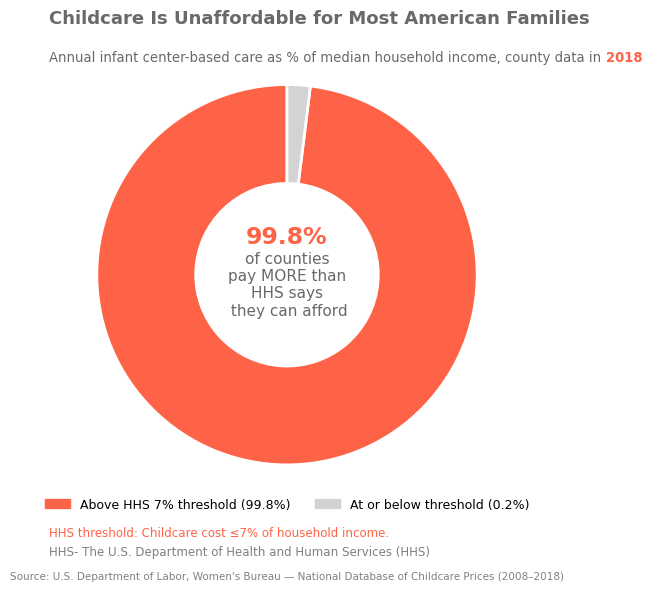

In [98]:
#Donut Chart 

#  Data 
# Last 3 years 2016-2018
df_last3  = df[df['StudyYear'].isin([2018])]
pct_above = (df_last3['infant_pct_income'].dropna() > 7).mean() * 100
pct_below = 100 - pct_above

# Chart 
fig, ax = plt.subplots(figsize=(7, 6))
#fig.patch.set_facecolor('#fffdf7') # white
#ax.set_facecolor('#fffdf7') # white
fig.patch.set_facecolor('white') # white
ax.set_facecolor('white') # white

# Force minimum visible slice for below-threshold
sizes_d  = [pct_above, max(pct_below, 2)]
colors_d = [TOMATO, LIGHT]

wedges, _ = ax.pie(
    sizes_d, colors=colors_d, startangle=90,
    wedgeprops={'width': 0.52, 'edgecolor': 'white', 'linewidth': 2})

# Center text fits inside the ring
ax.text(0,  0.2, f'{pct_above:.1f}%',
        ha='center', va='center',
        fontsize=17, fontweight='bold', color=TOMATO)
ax.text(0, -0.05, 'of counties\npay MORE than\nHHS says\n they can afford',
        ha='center', va='center',
        fontsize=11, color=DARK, linespacing=1.2)

# Legend
legend_patches = [
    mpatches.Patch(color=TOMATO, label=f'Above HHS 7% threshold ({pct_above:.1f}%)'),
    mpatches.Patch(color=LIGHT,  label=f'At or below threshold ({pct_below:.1f}%)'),
]
ax.legend(handles=legend_patches,
          loc='lower center', bbox_to_anchor=(0.5, -0.02),
          fontsize=9, frameon=False, ncol=2)

ax.set_title('Childcare Is Unaffordable for Most American Families',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=10)

# ax.text(0, 0.95, r'Annual infant center-based care as % of median household income in $\mathbf{2018}$ county data', ha='left', transform=ax.transAxes, fontsize=9.5, color=DARK)


# main text
ax.text(0.0, 0.95, 
        'Annual infant center-based care as % of median household income, county data in ',
        ha='left', transform=ax.transAxes, fontsize=9.5, color=DARK)

# "2018" in tomato
ax.text(1.17, 0.95, '2018',
        ha='left', transform=ax.transAxes, fontsize=9.5, 
        color=TOMATO, fontweight='bold')

ax.text(0.0, -0.05, 
        "HHS threshold: Childcare cost ≤7% of household income.",
        ha='left', transform=ax.transAxes, 
        fontsize=8.5, color=TOMATO, linespacing=1.4)

ax.text(0.0, -0.09, 
        "HHS- The U.S. Department of Health and Human Services (HHS)",
        ha='left', transform=ax.transAxes, 
        fontsize=8.5, color=GRAY, linespacing=1.4)


ax.text(0.5, -0.14, SOURCE, fontsize=7.5, color=GRAY,
        ha='center', transform=ax.transAxes)

plt.tight_layout()
plt.show()



Only 2 in every 1,000 counties met the federal affordability threshold, everywhere else families were overpaying. 
    
99.8% of Counties Cannot Afford Childcare by Federal Standards in 2018

#### V15 Slope chart

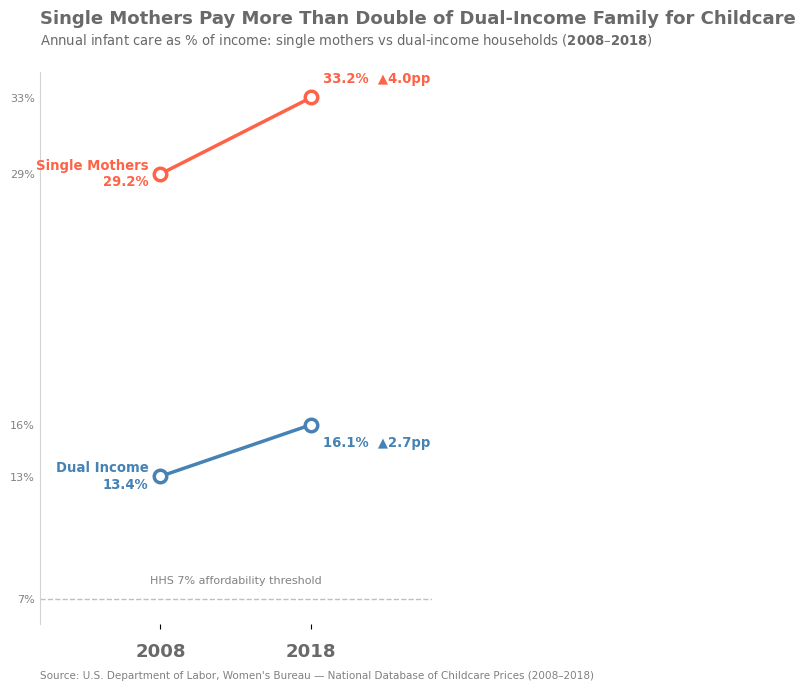

In [99]:
# Slope Chart
# Data  
groups    = ['Single Mothers', 'Dual Income']
colors_sl = [TOMATO, SBLUE]
vals_2008 = [29.2, 13.4]
vals_2018 = [33.2, 16.1]

# b2008 and b2018  for y-axis ticks
b2008 = vals_2008
b2018 = vals_2018

#  Chart  
fig, ax = plt.subplots(figsize=(6, 7))
# fig.patch.set_facecolor('#fffdf7') # white
# ax.set_facecolor('#fffdf7') # white
fig.patch.set_facecolor('white')  
ax.set_facecolor('white') 

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(True)
ax.spines['left'].set_color(LIGHT)
ax.spines['bottom'].set_visible(False)

x = [0, 1]
for i, (grp, c, v08, v18) in enumerate(zip(groups, colors_sl, vals_2008, vals_2018)):
    ax.plot(x, [v08, v18],
            color=c, linewidth=2.5,
            marker='o', markersize=9,
            markerfacecolor='white',
            markeredgecolor=c, markeredgewidth=2.5,
            zorder=3)

    # Left label
    ax.text(-0.08, v08, f'{grp}\n{v08:.1f}%',
            ha='right', va='center', fontsize=9.5,
            color=c, fontweight='bold')

    # Right label
    v_align = 'bottom' if i == 0 else 'top'
    y_off   = 0.6 if i == 0 else -0.6
    chg     = v18 - v08
    arrow   = '▲' if chg > 0 else '▼'
    ax.text(1.08, v18 + y_off,
            f'{v18:.1f}%  {arrow}{abs(chg):.1f}pp',
            ha='left', va=v_align, fontsize=9.5,
            color=c, fontweight='bold', clip_on=False)

# HHS threshold line
ax.axhline(7, color=GRAY, linewidth=1, linestyle='--', alpha=0.5)
ax.text(0.5, 7.8, 'HHS 7% affordability threshold',
        ha='center', fontsize=8, color=GRAY)

# Y axis ticks
ax.set_yticks([7, b2008[1], b2018[1], b2008[0], b2018[0]])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.tick_params(axis='y', labelsize=8, colors=GRAY, length=0)

# X axis
ax.set_xticks([0, 1])
ax.set_xticklabels([])
ax.set_xlim(-0.8, 1.8)

# Year labels at bottom
y_min  = ax.get_ylim()[0]
offset = (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.06
ax.text(0, y_min - offset, '2008',
        ha='center', fontsize=13, fontweight='bold',
        color=DARK, clip_on=False)
ax.text(1, y_min - offset, '2018',
        ha='center', fontsize=13, fontweight='bold',
        color=DARK, clip_on=False)

# Title and subtitle
ax.set_title('Single Mothers Pay More Than Double of Dual-Income Family for Childcare',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=35)
ax.text(0, 1.05,
        r'Annual infant care as % of income: single mothers vs dual-income households ($\mathbf{2008}$–$\mathbf{2018}$)',
        transform=ax.transAxes, fontsize=9.5, color=DARK)
ax.text(0, -0.10, SOURCE, fontsize=7.5, color=GRAY,
        transform=ax.transAxes)

plt.tight_layout()
plt.show()

In 2008 single mothers spent 29.2% of their household income on infant care — already four times the HHS affordable threshold of 7%. By 2018 this had risen to 33.2%, meaning single mothers now spend one third of their entire income on childcare alone.

Single mothers spend 33.2% of their income on childcare, it is more than double dual-income families and nearly five times the HHS affordable threshold.

### V16 - Stream  Chart

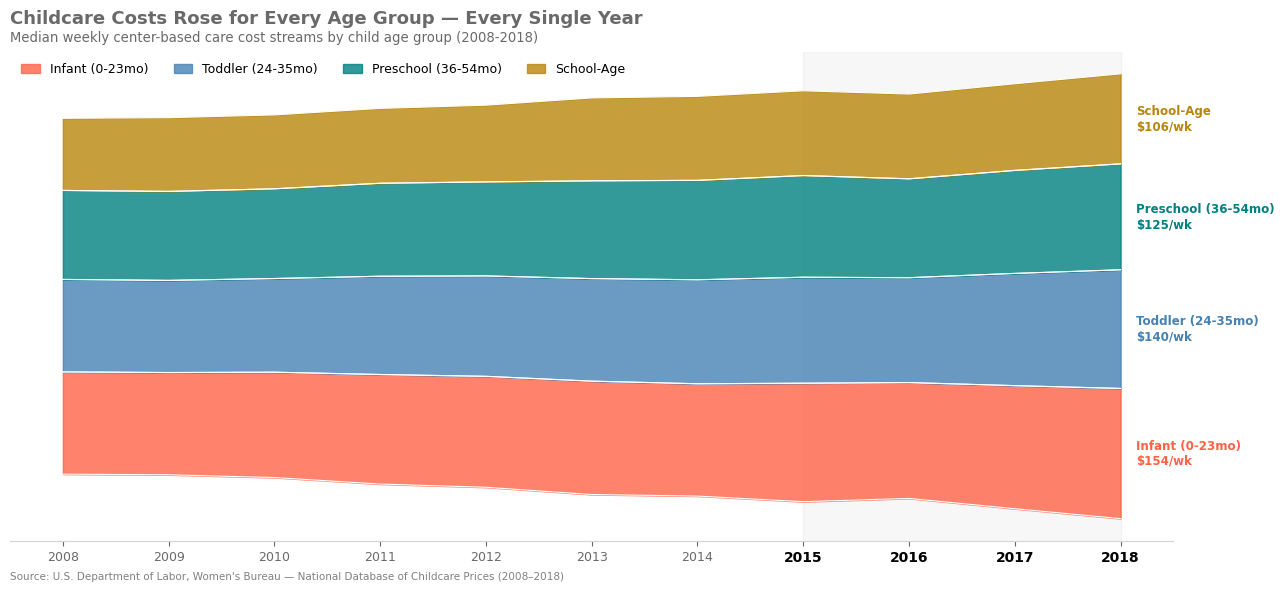

In [104]:
# Streamgraph 

# Data
stream_df = (df.groupby('StudyYear')
               .agg(
                   Infant    = ('MCInfant',    'median'),
                   Toddler   = ('MCToddler',   'median'),
                   Preschool = ('MCPreschool', 'median'),
                   SchoolAge = ('MCSA',        'median'))
               .reset_index())

years = stream_df['StudyYear'].values

# Stack baseline centered
inf = stream_df['Infant'].values
tod = stream_df['Toddler'].values
pre = stream_df['Preschool'].values
sa  = stream_df['SchoolAge'].values

total = inf + tod + pre + sa
baseline = -total / 2

# Cumulative stacks from baseline
y1_lo = baseline
y1_hi = baseline + inf

y2_lo = y1_hi
y2_hi = y2_lo + tod

y3_lo = y2_hi
y3_hi = y3_lo + pre

y4_lo = y3_hi
y4_hi = y4_lo + sa

# Chart 
fig, ax = plt.subplots(figsize=(13, 6))
# fig.patch.set_facecolor('#fffdf7') # white
# ax.set_facecolor('#fffdf7') # white
fig.patch.set_facecolor('white')  
ax.set_facecolor('white') 

style_ax(ax)
ax.spines['left'].set_visible(False)
ax.set_yticks([])

colors_s = [TOMATO, SBLUE, TEAL, AMBER]
labels_s = ['Infant (0-23mo)', 'Toddler (24-35mo)',
            'Preschool (36-54mo)', 'School-Age']

for lo, hi, color, label in zip(
        [y1_lo, y2_lo, y3_lo, y4_lo],
        [y1_hi, y2_hi, y3_hi, y4_hi],
        colors_s, labels_s):
    ax.fill_between(years, lo, hi, alpha=0.80,
                    color=color, label=label)
    ax.plot(years, lo, color='white', linewidth=0.8)
    ax.plot(years, hi, color='white', linewidth=0.8)

    # Inline label at 2018
    mid = (lo[-1] + hi[-1]) / 2
    val = hi[-1] - lo[-1]
    ax.text(2018.15, mid, f'{label}\n${val:.0f}/wk',
            fontsize=8.5, color=color, fontweight='bold',
            va='center', clip_on=False)

# Shade 2015-2018
ax.axvspan(2015, 2018, alpha=0.05, color=DARK, zorder=0)

ax.set_xticks(years)
ax.tick_params(axis='x', labelsize=9)

# Bold 2015-2018 x labels
fig.canvas.draw()
for label in ax.get_xticklabels():
    txt = label.get_text()
    if txt.isdigit() and int(txt) >= 2015:
        label.set_color(BLACK); label.set_fontweight('bold'); label.set_fontsize(10)
    else:
        label.set_color(DARK); label.set_fontweight('normal'); label.set_fontsize(9)

ax.set_title('Childcare Costs Rose for Every Age Group — Every Single Year',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=20)
ax.text(0, 1.02,
        'Median weekly center-based care cost streams by child age group (2008-2018)',
        transform=ax.transAxes, fontsize=9.5, color=DARK)

ax.legend(loc='upper left', bbox_to_anchor=(0, 1),
          fontsize=9, frameon=False, ncol=4, handlelength=1.5)

ax.text(0, -0.08, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)

plt.tight_layout()
plt.show()

Every single age group rose between 2008 and 2018. There was not a single year where costs fell across all four groups simultaneously.

The childcare cost burden on their employees grows regardless of the age of their children, and it is not just a newborn problem. 
Employees with toddlers, preschoolers, and school-age children are all affected.
Childcare support is relevant across your entire workforce, not just for new parents.

Every age group got more expensive every year, and infant care rose $33/week since 2008

#### Chart 17 – Horizontal Bar Chart

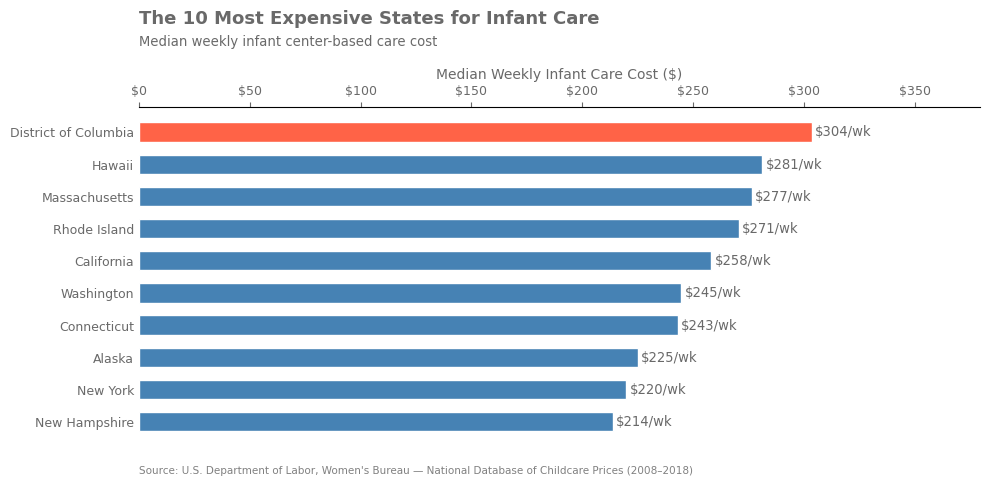

In [101]:
# Horizontal Bar Chart

# Data
state_avg = (df.groupby('State_Name')['MCInfant']
               .median()
               .dropna()
               .sort_values(ascending=False)
               .head(10)
               .sort_values(ascending=True))   # ascending for horizontal

# Chart 
fig, ax = plt.subplots(figsize=(10, 5))
# fig.patch.set_facecolor('#fffdf7') # white
# ax.set_facecolor('#fffdf7') # white
fig.patch.set_facecolor('white')  
ax.set_facecolor('white') 

style_ax(ax)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['top'].set_visible(True)

bar_colors = [TOMATO if v == state_avg.max() else SBLUE
              for v in state_avg.values]

bars = ax.barh(state_avg.index, state_avg.values,
               color=bar_colors, height=0.6, edgecolor='white')

# Value labels on bars
for bar in bars:
    w = bar.get_width()
    ax.text(w + 1.5, bar.get_y() + bar.get_height() / 2,
            f'${w:.0f}/wk', va='center', fontsize=9.5, color=DARK)

ax.set_xlabel('Median Weekly Infant Care Cost ($)', fontsize=10, color=DARK)
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}'))
ax.tick_params(axis='y', length=0, labelsize=9)
ax.set_xlim(0, state_avg.max() * 1.25)

ax.set_title('The 10 Most Expensive States for Infant Care',
             fontsize=13, fontweight='bold', color=DARK, loc='left', pad=60)
ax.text(0, 1.18,
        'Median weekly infant center-based care cost',
        transform=ax.transAxes, fontsize=9.5, color=DARK)

ax.text(0, -0.08, SOURCE, fontsize=7.5, color=GRAY, transform=ax.transAxes)

plt.tight_layout()
plt.show()


If Company has offices or employees in any of these 10 states, the female workforce is facing some of the most extreme childcare costs in the country. 

At $303/week in DC and $281/week in Hawaii, a working mother earning the median female salary of $22,855 would spend over 69% of her entire income on infant care alone in these states

In the District of Columbia infant care costs $303/week — $15,786 per year for one child alone.

### V18 Geo Map

Where you live determines what you pay, and for millions of American families the cost is simply too high.

West Coast states like Massachusetts, California, New York, and Washington face the highest weekly childcare bills in the country. 
Meanwhile families in Southern and Midwestern states pay significantly less

The most expensive childcare states are also biggest business hubs. Northeast and West Coast employers face the highest retention risk.
    


In [ ]:
import os
OUT = 'childcare_charts'
os.makedirs(OUT, exist_ok=True)

# print(os.getcwd())
# print(os.path.abspath(OUT))

In [515]:
# Geo Map Data — all years median (49 states)
geo_df = (df.groupby('State_Abbreviation')['MCInfant']
            .median()
            .reset_index()
            .dropna()
            .round(2))
geo_df.columns = ['State Code', 'Median Weekly Infant Cost']
geo_df['State Code'] = geo_df['State Code'].str.strip().str.upper()
print('States:', len(geo_df))

States: 49


In [516]:
geo_df.to_csv(f'{OUT}/DW_V4_geomap.csv', index=False)
print(f'Geo Map CSV: {len(geo_df)} states {OUT}/DW_V4_geomap.csv')

Geo Map CSV: 49 states → childcare_charts/DW_V4_geomap.csv
